# TODAY
* K-nearest neighbours algorithm
* Evaluation metrics
* Cross validation


# Classification with ScikitLearn
Scikit-learn includes many methods and functions for machine learning.

* We have a set of features to describe the examples, and we want to assign a "class" to our examples.

**Example**: *We have some samples of data whose features belong to the results of a chemical analysis of wines grown in the same region in Italy but derived from three different cultivars. The analysis determined the quantities of 13 constituents found in each of the three types of wines.*

**Metrics for evaluating Machine Learning models**: accuracy, precision, recall, F-measure.


In [2]:
import sklearn
from sklearn import datasets #import a built-in dataset from scikit-learn
import numpy as np

wine_dataset = datasets.load_wine() #Load wine dataset
print(wine_dataset.keys()) # print the keys of a "wine_dataset" object

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])


In [3]:
print(wine_dataset["DESCR"]) #Print the description of the dataset

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

In [4]:
# Access the data, targets, and other information in the dataset.
X = wine_dataset.data
y = wine_dataset.target
feature_names = wine_dataset.feature_names

In [5]:
print(X.shape) # Print the shape of the array X

(178, 13)


The output in this case might be "(178, 13)," which indicates that there are 178 rows and 13 columns in the data represented by "X." 178: is the number of samples in the wine dataset. 13: is the number of features in a single sample.

In [6]:
# Very important!!!!! Split the entire dataset into (a) training set, and (b) test set.
from sklearn.model_selection import train_test_split

# In this case, with a proportion of 25% of the data assigned to the test set.
# The "random_state" argument is used to control the reproducibility of the random split.
# The value "24" in this case is just an arbitrary number and could be replaced with any other integer.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=24)

In [7]:
# Very important!!!!! Split the training set into (a) training set, and (b) validation set.
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=32)

In [8]:
# Import the "KNeighborsClassifier" class from the "neighbors" module of the scikit-learn library.
# k-Nearest Neighbors, a machine learning algorithm used for classification problems.
# This classifier assigns a class to a data point based on the classes of the data points closest to it in the training set.

from sklearn.neighbors import KNeighborsClassifier

In [9]:
n_neighbors = 25 # Specify the desired number of neighbors
model = KNeighborsClassifier(n_neighbors) # The model is initialized to use 25 neighbors in the classification phase

In [10]:
# Fit model to data: the model will be trained using the training data X_train and the labels y_train.
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",25
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [11]:
# Validation
# "model" represents the K-Nearest Neighbors model that we trained earlier.
# predict() is a method to make predictions using the trained model.
# The array pred_val will contain the model's predictions for the validation data (X_val).

pred_val = model.predict(X_val)

In [12]:
pred_val

array([2, 1, 0, 2, 1, 0, 2, 2, 0, 0, 2, 2, 2, 2, 1, 1, 1, 2, 2, 1, 2, 0,
       2, 2, 2, 2, 0, 0, 1, 1, 2, 0, 0, 1])

### Metrics:
# Confusion Matrix for Binary Classification
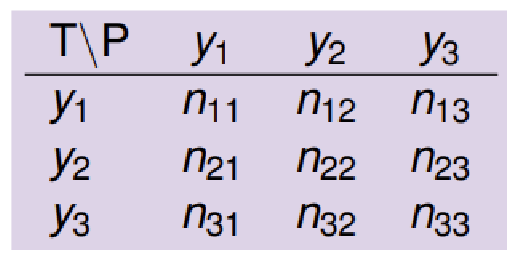


# Accuracy:
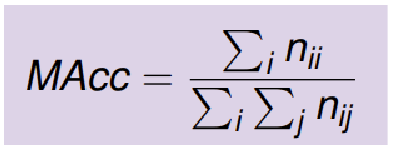
# Precision and Recall:
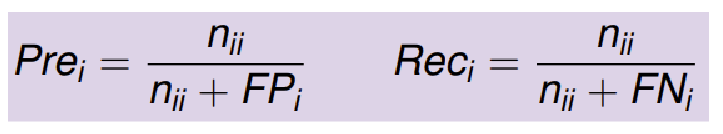



In [13]:
# Calculate accuracy
# "pred_val == y_val": This expression creates a boolean array where each element
# is True if the prediction matches the true label for the corresponding observation in the validation data, otherwise it is False.
# "np.mean(...)" calculates the fraction of "True" elements in a boolean array, thus representing the percentage of correct predictions out of the total predictions.
# y_val: Ground truth for validation data. Represents the true labels in the validation data.

accuracy = np.mean(pred_val == y_val)
print(f"Accuracy on validation set is: {accuracy}")

Accuracy on validation set is: 0.7058823529411765


In [14]:
# Calculating the Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# Calculate the confusion matrix based on the true labels "y_val" and the model predictions "pred_val"
print("The total amount of data predicted as 0:", sum(pred_val==0))
print("The total amount of data that is 0 in reality:", sum(y_val==0))
print("The total amount of data predicted as 1:", sum(pred_val==1))
print("The total amount of data that is 1 in reality:", sum(y_val==1))
print("The total amount of data predicted as 2:", sum(pred_val==2))
print("The total amount of data that is 2 in reality:", sum(y_val==2))
cm = confusion_matrix(y_val, pred_val)

The total amount of data predicted as 0: 9
The total amount of data that is 0 in reality: 7
The total amount of data predicted as 1: 9
The total amount of data that is 1 in reality: 14
The total amount of data predicted as 2: 16
The total amount of data that is 2 in reality: 13


In [15]:
cm
# Note that the sum of each row corresponds to the ground truth.
# Note that the sum of each column represents the total predictions made by the model for each class.

array([[ 6,  0,  1],
       [ 1,  8,  5],
       [ 2,  1, 10]])

In [22]:
%pip install matplotlib

ERROR:root:code for hash blake2b was not found.
Traceback (most recent call last):
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 307, in <module>
    globals()[__func_name] = __get_hash(__func_name)
                             ^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 129, in __get_openssl_constructor
    return __get_builtin_constructor(name)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 123, in __get_builtin_constructor
    raise ValueError('unsupported hash type ' + name)
ValueError: unsupported hash type blake2b
ERROR:root:code for hash blake2s was not found.
Traceback (most recent call last):
  File "/Users/andreatoffali/.pyenv/versions/3.11.9/lib/python3.11/hashlib.py", line 307, in <module>
    globals()[__func_name] = __get_hash(__func_name)
                             ^^^^^^^^^^^^^^^^^^^^^^

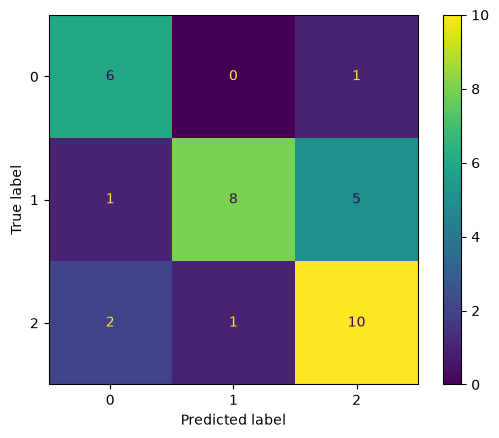

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
# How to graphically represent the confusion matrix?
ConfusionMatrixDisplay(cm).plot()
# a confusion matrix plot using the default settings

In [17]:
# Can we modify the graph settings?
help(ConfusionMatrixDisplay)
# Read the following output at home.

Help on class ConfusionMatrixDisplay in module sklearn.metrics._plot.confusion_matrix:

class ConfusionMatrixDisplay(builtins.object)
 |  ConfusionMatrixDisplay(confusion_matrix, *, display_labels=None)
 |  
 |  Confusion Matrix visualization.
 |  
 |  It is recommended to use
 |  :func:`~sklearn.metrics.ConfusionMatrixDisplay.from_estimator` or
 |  :func:`~sklearn.metrics.ConfusionMatrixDisplay.from_predictions` to
 |  create a :class:`ConfusionMatrixDisplay`. All parameters are stored as
 |  attributes.
 |  
 |  For general information regarding `scikit-learn` visualization tools, see
 |  the :ref:`Visualization Guide <visualizations>`.
 |  For guidance on interpreting these plots, refer to the
 |  :ref:`Model Evaluation Guide <confusion_matrix>`.
 |  
 |  Parameters
 |  ----------
 |  confusion_matrix : ndarray of shape (n_classes, n_classes)
 |      Confusion matrix.
 |  
 |  display_labels : ndarray of shape (n_classes,), default=None
 |      Display labels for plot. If None, disp

In [18]:
# Calculate accuracy, recall, and precision with scikit-learn
accuracy = sklearn.metrics.accuracy_score(y_val, pred_val)
recall = sklearn.metrics.recall_score(y_val, pred_val, average="macro")
precision = sklearn.metrics.precision_score(y_val, pred_val, average="macro")

# macro: This parameter specifies how to calculate recall in the case of multiclass problems.
# The "macro" option calculates the recall for each class and returns the unweighted average of these values.
# It is useful when you want to obtain a measure of overall recall that considers all classes equally.
# IMPORTANT: "Macro" is a valid choice when we want a balanced evaluation metric for imbalanced classification problems.

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

Accuracy: 0.7058823529411765
Precision: 0.7268518518518517
Recall: 0.7326007326007326


## Exercise

1. For the wine dataset and the k-NN method, write a code to select the best hyperparameter based on validation performance.

2. A better way of performing model validation is applying k-fold cross validation. See `sklearn.model_selection.cross_val_score` and `sklearn.model_selection.ShuffleSplit` to implement k-fold cross validation when k=2 and k=3.


## Point 1.
  - For the wine dataset and the k-NN method, write a code to select the best hyperparameter based on validation performance.

In [19]:
print(X_train.shape, X_val.shape, X_test.shape)

(99, 13) (34, 13) (45, 13)


Starting with specifying the desired number of neighbors

In [20]:
n_neighbors = 1 # start with a very little value
model = KNeighborsClassifier(n_neighbors) # the model is initialized to use 1 neighbor in the classification phase

In [21]:
# Fit the model to data: the model will be trained using the training data X_train and the labels y_train
model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


The next step is the validation

In [22]:
# Validation
# "model" represents the K-Nearest Neighbors model that we trained erlier.
# predict() is a method to make predictions using the trained model
# The array pred_val will contain the model's predictions for the validation data (X_val).
pred_val = model.predict(X_val)

In [23]:
pred_val

array([2, 1, 0, 1, 1, 2, 2, 0, 0, 0, 1, 2, 2, 2, 1, 1, 1, 2, 1, 1, 1, 0,
       2, 0, 1, 1, 0, 0, 1, 2, 2, 0, 0, 2])

# Confusion Matrix for Binary Classification

## Precision and Recall: 

In [24]:
# Calculate accuracy
# "pred_val == y_val": This expression creates a boolean array where each element
# is True fi the prediction mathces the true label for the corresponding observation in the validation data, otherwise it is False
# "np.mean()" calculates the fraction of "True" elements in a boolean array, thus representing 
# the percentage of correct prediction
# y_val: Ground truth for validation data. Represent the true labels in the validation data.

accuracy = np.mean(pred_val == y_val)
print(f"Accuracy on validation set is: {accuracy}")

Accuracy on validation set is: 0.6764705882352942


In [26]:
# Calculating the Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("The total amount of data predicted as 0:", sum(pred_val == 0))
print("The total amount of data predicted as 0 in reality:", sum(y_val == 0))
print("The total amount of data predicted as 1:", sum(pred_val == 1))
print("The total amount of data predicted as 1 in reality:", sum(y_val == 1))
print("The total amount of data predicted as 2:", sum(pred_val == 2))
print("The total amount of data predicted as 2 in reality:", sum(y_val == 2))
cm = confusion_matrix(y_val, pred_val)

The total amount of data predicted as 0: 10
The total amount of data predicted as 0 in reality: 7
The total amount of data predicted as 1: 13
The total amount of data predicted as 1 in reality: 14
The total amount of data predicted as 2: 11
The total amount of data predicted as 2 in reality: 13


In [28]:
cm 

array([[6, 1, 0],
       [2, 9, 3],
       [2, 3, 8]])

### Graphical representation of the confusion matrix

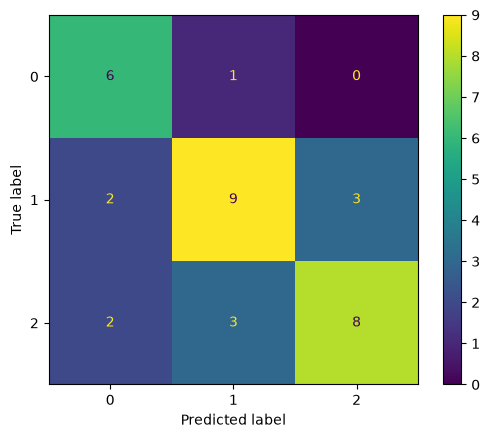

In [29]:
ConfusionMatrixDisplay(cm).plot()

### Now let's calculate the accuracy, recall, and precision with scikit-learn

In [30]:
accuracy = sklearn.metrics.accuracy_score(y_val, pred_val)
recall = sklearn.metrics.recall_score(y_val, pred_val, average="macro")
precision = sklearn.metrics.precision_score(y_val, pred_val, average="macro")

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

Accuracy: 0.6764705882352942
Precision: 0.6731934731934732
Recall: 0.7051282051282052


### Now let's use another value for the K-NN

Let's try with the value of 5, in order to see the difference between the two last tried.

In [31]:
n_neighbors = 5
model = KNeighborsClassifier(n_neighbors)
model.fit(X_train, y_train)
pred_val = model.predict(X_val)
pred_val

array([2, 1, 0, 2, 1, 0, 2, 0, 0, 0, 1, 2, 2, 2, 1, 1, 1, 2, 2, 1, 2, 0,
       2, 0, 2, 1, 0, 0, 1, 1, 1, 0, 0, 2])

In [32]:
accuracy = np.mean(pred_val == y_val)
print(f"Accuracy on validation set is: {accuracy}")

Accuracy on validation set is: 0.6764705882352942


In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print("The total amount of data predicted as 0:", sum(pred_val == 0))
print("The total amount of data predicted as 0 in reality:", sum(y_val == 0))
print("The total amount of data predicted as 1:", sum(pred_val == 1))
print("The total amount of data predicted as 1 in reality:", sum(y_val == 1))
print("The total amount of data predicted as 2:", sum(pred_val == 2))
print("The total amount of data predicted as 2 in reality:", sum(y_val == 2))
cm = confusion_matrix(y_val, pred_val)

The total amount of data predicted as 0: 11
The total amount of data predicted as 0 in reality: 7
The total amount of data predicted as 1: 11
The total amount of data predicted as 1 in reality: 14
The total amount of data predicted as 2: 12
The total amount of data predicted as 2 in reality: 13


In [34]:
cm

array([[6, 0, 1],
       [2, 9, 3],
       [3, 2, 8]])

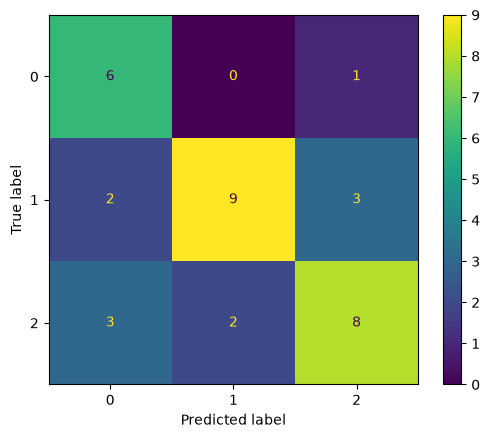

In [35]:
ConfusionMatrixDisplay(cm).plot()

In [36]:
accuracy = sklearn.metrics.accuracy_score(y_val, pred_val)
recall = sklearn.metrics.recall_score(y_val, pred_val, average="macro")
precision = sklearn.metrics.precision_score(y_val, pred_val, average="macro")

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")

Accuracy: 0.6764705882352942
Precision: 0.6767676767676768
Recall: 0.7051282051282052


## Now let's automized the process of valutation about the K-NN, with a for cicle

K= 1 | accuracy=0.676 | precision=0.673 | recall=0.705
K= 2 | accuracy=0.529 | precision=0.533 | recall=0.573
K= 3 | accuracy=0.706 | precision=0.703 | recall=0.731
K= 4 | accuracy=0.676 | precision=0.681 | recall=0.703
K= 5 | accuracy=0.676 | precision=0.677 | recall=0.705
K= 6 | accuracy=0.618 | precision=0.622 | recall=0.654
K= 7 | accuracy=0.647 | precision=0.648 | recall=0.681
K= 8 | accuracy=0.559 | precision=0.554 | recall=0.603
K= 9 | accuracy=0.676 | precision=0.681 | recall=0.707
K=10 | accuracy=0.588 | precision=0.585 | recall=0.628
K=11 | accuracy=0.676 | precision=0.672 | recall=0.705
K=12 | accuracy=0.618 | precision=0.622 | recall=0.656
K=13 | accuracy=0.676 | precision=0.681 | recall=0.707
K=14 | accuracy=0.647 | precision=0.657 | recall=0.681
K=15 | accuracy=0.676 | precision=0.681 | recall=0.707
K=16 | accuracy=0.706 | precision=0.727 | recall=0.733
K=17 | accuracy=0.735 | precision=0.744 | recall=0.756
K=18 | accuracy=0.618 | precision=0.613 | recall=0.654
K=19 | acc

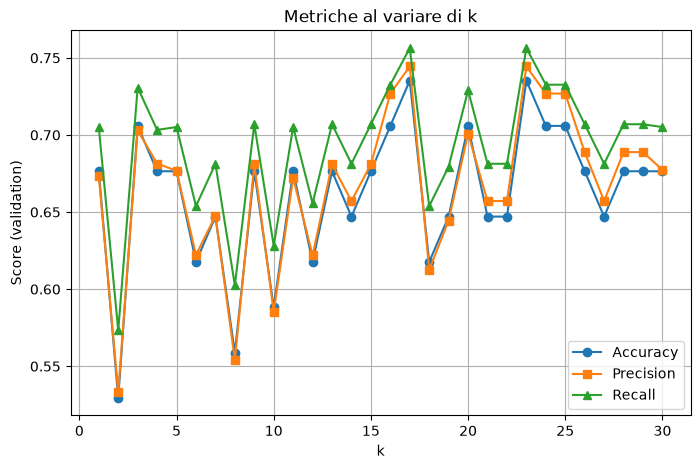

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score 

value_k = range(1, 31)
accuracy_val = []
precision_val = []
recall_val = []

for k in value_k:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    pred_val = model.predict(X_val)

    accuracy = accuracy_score(y_val, pred_val)
    precision = precision_score(y_val, pred_val, average="macro")
    recall = recall_score(y_val, pred_val, average="macro")

    accuracy_val.append(accuracy)
    precision_val.append(precision)
    recall_val.append(recall)

    print(f"K={k:2d} | accuracy={accuracy:.3f} | precision={precision:.3f} | recall={recall:.3f}")

# Graphical visualization
plt.figure(figsize=(8, 5))
plt.plot(value_k, accuracy_val, marker='o', label='Accuracy')
plt.plot(value_k, precision_val, marker='s', label='Precision')
plt.plot(value_k, recall_val, marker='^', label='Recall')
plt.xlabel('k')
plt.ylabel('Score (validation)')
plt.title('Metriche al variare di k')
plt.legend()
plt.grid(True)
plt.show()

## Point 2
  - A better way of performing model validation is appling the k-fold cross validation. See `sklearn.model_selection.cross_val_score` and `sklearn.model_selection.ShuffleSplit` to implement k-fold cross validation when k=2 and k=3.

### So now implement the method 

2 split -> miglior k = 1, accuracy = 0.750
3 split -> miglior k = 3, accuracy = 0.711


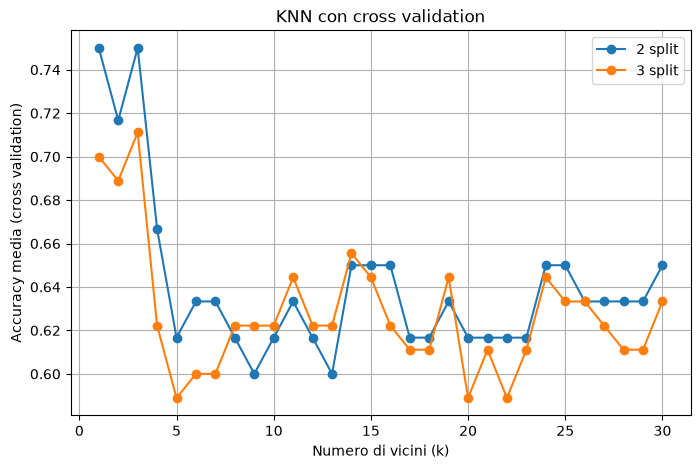

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, ShuffleSplit

value_k = range(1,31)
cross_validation_result = {}


for n_splits in [2, 3]:
    cv = ShuffleSplit(n_splits=n_splits, test_size=0.3, random_state=42)
    mean_scores = []

    for k in value_k:
        model = KNeighborsClassifier(n_neighbors=k)
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
        mean_scores.append(scores.mean())

    cross_validation_result[n_splits] = mean_scores

    best_k = value_k[int(np.argmax(mean_scores))]
    print(f"{n_splits} split -> miglior k = {best_k}, accuracy = {max(mean_scores):.3f}")


plt.figure(figsize=(8, 5))
for n_splits, scores in cross_validation_result.items():
    plt.plot(value_k, scores, marker='o', label=f'{n_splits} split')
plt.xlabel('Numero di vicini (k)')
plt.ylabel('Accuracy media (cross validation)')
plt.title('KNN con cross validation')
plt.legend()
plt.grid(True)
plt.show()
